# Eksplorasi Data Pengangguran Kabupaten Tuban

Notebook awal untuk laporan kerja praktik. Sumber utama: `Datasets/Data_Pengangguran_Clean_Audited_8_Sep_2026.csv`. Analisis ini merangkum jumlah pada data sumber; bukan analisis sebab-akibat.

## Ruang lingkup

Unit baris adalah wilayah desa/kelurahan pada CSV. Notebook memeriksa kelengkapan, menjumlahkan `Total_Penganggur` dan `Total_Penduduk_Bekerja` menurut kecamatan, lalu menampilkan kolom QC. Pastikan periode data, definisi indikator, dan denominator dikonfirmasi sebelum menghitung tingkat atau persentase pengangguran.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

from laporan_kerja_praktik import load_dataset, summarize_by_district

data = load_dataset()
print(f"Cakupan: {len(data):,} baris × {len(data.columns)} kolom")
print(f"Jumlah kecamatan: {data['kecamatan'].nunique()}")
print(f"Jenis wilayah: {', '.join(sorted(data['jenis_kd'].dropna().unique()))}")

Cakupan: 328 baris × 96 kolom
Jumlah kecamatan: 20
Jenis wilayah: Desa, Kelurahan


## Contoh baris

Tampilkan kolom inti saja agar identitas wilayah, jumlah penganggur, dan jumlah penduduk bekerja mudah diperiksa.

In [2]:
display(
    data[["kecamatan", "kel_desa", "Total_Penganggur", "Total_Penduduk_Bekerja"]]
    .head()
)

,kecamatan,kel_desa,Total_Penganggur,Total_Penduduk_Bekerja
0,Plumpang,Bandungrejo,277,657
1,Soko,Bangunrejo,440,892
2,Widang,Banjar,198,265
3,Rengel,Banjaragung,384,941
4,Rengel,Banjararum,457,890


## Pemeriksaan nilai kosong

Header `#N/A` berasal dari CSV sumber; jangan menafsirkannya sebagai indikator tanpa klarifikasi.

In [3]:
missing = data.isna().sum().sort_values(ascending=False)
display(missing[missing.gt(0)].to_frame("jumlah_kosong").head(20))

,jumlah_kosong


## Ringkasan per kecamatan

Angka di bawah adalah jumlah agregat dari kolom sumber, bukan tingkat pengangguran. Perbandingan jumlah juga dipengaruhi ukuran populasi wilayah.

In [4]:
ringkasan_kecamatan = summarize_by_district(data)
display(ringkasan_kecamatan)

,kecamatan,Total_Penganggur,Total_Penduduk_Bekerja
0,Semanding,13017,29688
1,Soko,10474,20401
2,Palang,10400,21673
3,Plumpang,9643,18763
4,Tuban,9509,20229
5,Parengan,7495,14015
6,Kerek,7213,19673
7,Rengel,7140,14808
8,Merakurak,6965,16063
9,Bangilan,6671,12572


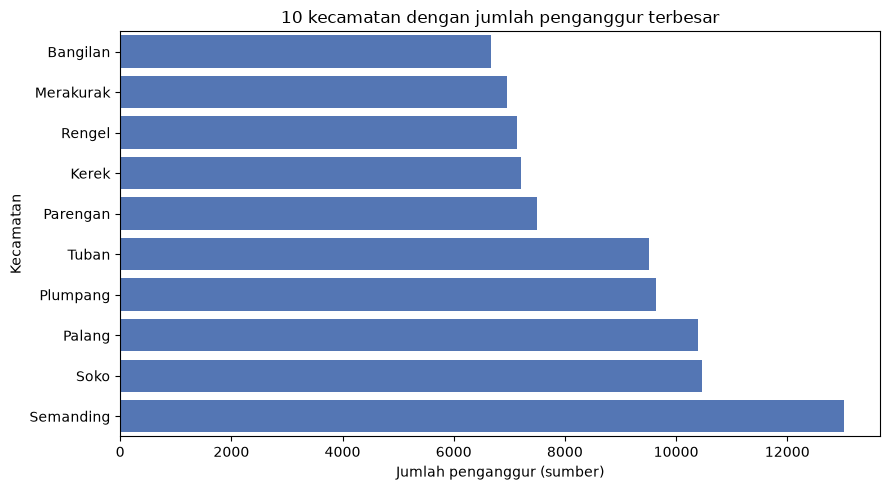

In [5]:
top_10 = ringkasan_kecamatan.nlargest(10, "Total_Penganggur").sort_values("Total_Penganggur")

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=top_10, x="Total_Penganggur", y="kecamatan", color="#4472C4", ax=ax)
ax.set(title="10 kecamatan dengan jumlah penganggur terbesar", xlabel="Jumlah penganggur (sumber)", ylabel="Kecamatan")
fig.tight_layout()
plt.show()

## Ringkasan menurut jenis wilayah

Jumlah baris ditampilkan sebagai hitungan unit yang tercatat. Periksa kamus data dan aturan pencatatan sebelum menyamakan unit antarjenis wilayah.

In [6]:
ringkasan_jenis = (
    data.groupby("jenis_kd", dropna=False)
    .agg(
        jumlah_baris=("kel_desa", "count"),
        jumlah_penganggur=("Total_Penganggur", "sum"),
        jumlah_bekerja=("Total_Penduduk_Bekerja", "sum"),
    )
    .reset_index()
)
display(ringkasan_jenis)

,jenis_kd,jumlah_baris,jumlah_penganggur,jumlah_bekerja
0,Desa,311,130382,292957
1,Kelurahan,17,11786,23568


## Pemeriksaan kualitas sumber

Ringkasan ini mempertahankan nilai QC apa adanya. Tinjau definisi setiap pemeriksaan sebelum memutuskan baris mana yang layak dimasukkan ke analisis.

In [7]:
kolom_qc = [column for column in data.columns if column.startswith("QC_")]
for column in kolom_qc:
    hitung = data[column].value_counts(dropna=False).rename("jumlah").rename_axis("nilai").reset_index()
    hitung.insert(0, "kolom_qc", column)
    display(hitung)

,kolom_qc,nilai,jumlah
0,QC_Penyakit_Total,OK,328


,kolom_qc,nilai,jumlah
0,QC_Partisi_Penganggur,OK,328


,kolom_qc,nilai,jumlah
0,QC_Kode_Unik,OK,328


,kolom_qc,nilai,jumlah
0,QC_Nama_Alias,SAMA,316
1,QC_Nama_Alias,ALIAS,12


,kolom_qc,nilai,jumlah
0,QC_KeyJoin_Unik,OK,328


,kolom_qc,nilai,jumlah
0,QC_KeyJoin_Blok,OK,328


## Catatan untuk pembahasan laporan

Gunakan tabel dan grafik di atas untuk menyusun pembahasan sesuai rumusan masalah. Cantumkan kecamatan/kelompok yang dibandingkan, satuan hitungan, periode sumber yang telah dikonfirmasi, temuan QC yang relevan, dan batas interpretasi. Untuk proporsi atau tingkat pengangguran, definisikan denominator terlebih dahulu dan jelaskan dasar pemilihannya.